<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/06_Lab_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Notebook basado en biotrain latam https://github.com/biotrain-latam/BiotrAIn-pilot-course, 

# Deep Learning for Molecular Property Prediction: A Comprehensive Guide

Welcome to this comprehensive deep learning tutorial! We'll explore how to build and train neural networks for predicting molecular properties, specifically solubility.

## What We'll Cover

1. **Setting up**
   - Install libraries and download data
   - Pytorch

1. **Data Understanding & Exploration**
   - Dataset analysis and visualization
   - Molecular descriptors
   - Data spliting

2. **Deep Learning Fundamentals**
   - What is a neural network?
   - Architecture components
   - Hyperparameters explanation

3. **Model Development**
   - Building a neural network from scratch
   - Training process understanding
   - Hyperparameter optimization using grid search

4. **Model Evaluation**
   - Performance metrics
   - Results analysis



# **1. Setting up**

### **Install libraries and download data**

In [46]:
# Install all libraries
! pip install pytorch-lightning wandb rdkit ogb deepchem torch

# Download all data (usando un espejo confiable del dataset ESOL)
import os
import requests

os.makedirs("data", exist_ok=True)
destino = "data/ci034243x_si_001.txt"

url_mirror = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
headers = {"User-Agent": "Mozilla/5.0"}

resp = requests.get(url_mirror, headers=headers, timeout=30)
print("Código de estado HTTP:", resp.status_code)
print("Bytes descargados:", len(resp.content))

with open(destino, "wb") as f:
    f.write(resp.content)

print("Tamaño del archivo guardado:", os.path.getsize(destino), "bytes")


[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Código de estado HTTP: 200
Bytes descargados: 96699
Tamaño del archivo guardado: 96699 bytes


In [48]:
import pandas as pd

df = pd.read_csv("data/ci034243x_si_001.txt")
df

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl
...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O


### **Pytorch**
#### What is Pytorch?
Based on the Torch library, PyTorch is one of the most popular deep learning frameworks for machine learning practitioners. We will learn to use PyTorch to do deep learning work. You can also browse the PyTorch [tutorials](https://pytorch.org/tutorials/) and [docs](https://pytorch.org/docs/stable/index.html) for additional details.

#### Pytorch Lightning
PyTorch Lightning is the deep learning framework for professional AI researchers and machine learning engineers who need maximal flexibility without sacrificing performance at scale. You can also browse its [documentation](https://pytorch-lightning.readthedocs.io/en/stable/) for additional details.

Let´s start by setting a random seed to ensure repeatability of experiments

In [49]:
import random
import numpy as np
import torch

# Random Seeds and Reproducibility
# Cuando se crea la red, cada peso (θ) de cada capa se inicializa con un valor aleatorio pequeño
torch.manual_seed(0)            # fija en 0 el punto de partida del generador de números aleatorios que usa PyTorch en CPU
torch.cuda.manual_seed(0)       # fija en 0 el punto de partida del generador de números aleatorios que usa PyTorch en GPU
np.random.seed(0)               # fija en 0 el punto de partida del generador de números aleatorios que usa NumPy
random.seed(0)                  # fija en 0 el punto de partida del generador de números aleatorios que usa Python   

# **2. Understanding Our Data**

## The ESOL Dataset
We're working with the [ESOL](https://acs.figshare.com/articles/dataset/ESOL_Estimating_Aqueous_Solubility_Directly_from_Molecular_Structure/7944677?file=14790314) (Estimated SOLubility) dataset, which contains:
- **Compound ID**: Unique identifier for each compound.
- **Measured log(solubility:mol/L)**: Experimental solubility values in log mol/L.
- **ESOL predicted log(solubility:mol/L)**: Predicted solubility values using the ESOL method.
- **SMILES**: Simplified Molecular Input Line Entry System representation of the molecular structure.

### What is SMILES?
SMILES (Simplified Molecular Input Line Entry System) is a line notation for describing the structure of chemical species using short ASCII strings. For example:
- `CC(=O)O` represents acetic acid (CH₃COOH)
- `C1=CC=CC=C1` represents benzene
- `O` represents water (H₂O)

Key SMILES syntax:
- Letters represent atoms (C=carbon, O=oxygen, N=nitrogen, etc.)
- Numbers indicate rings
- `=` represents double bonds
- `#` represents triple bonds
- Branching is shown with parentheses
- Square brackets `[]` are used for more complex cases

Here is an example of a molecule represented as SMILES
<div align="left">
    <figure>
        <img src="Example_SMILES.png" alt="Molecule SMILES Example" width="400"/>
        <figcaption><i>Example of a molecule and its SMILES representation</i></figcaption>
    </figure>
</div>

### Why Solubility Prediction?
Solubility is a crucial property in drug development and chemical processes. Accurate prediction can:
- Speed up drug discovery
- Reduce experimental costs
- Help in formulation development

### Data Preprocessing
Let's start by exploring our data:



In [50]:
! pip install seaborn matplotlib


[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from rdkit import Chem  # Es el que convierte un texto SMILES en un objeto molécula que la computadora puede manipular. Sin esto, un SMILES es solo una cadena de texto sin significado químico para el programa
from rdkit.Chem import Draw, AllChem  # Sirve para generar imágenes de las moléculas

# TODO: Load ESOL data in a pandas dataframe keeping only "measured log" and "SMILES" columns
# then show the first 5 rows of your dataframe


In [52]:
df = pd.read_csv("data/ci034243x_si_001.txt")
df = df.rename(columns={
    "smiles": "SMILES",
    "measured log solubility in mols per litre": "measured log(solubility:mol/L)"
})
df

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl
...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O


In [53]:
Cols = ["measured log(solubility:mol/L)", "SMILES"]
df = df[Cols]
df.head()

,measured log(solubility:mol/L),SMILES
0,-2.18,ClCC(Cl)(Cl)Cl
1,-2.00,CC(Cl)(Cl)Cl
2,-1.74,ClC(Cl)C(Cl)Cl
3,-1.48,ClCC(Cl)Cl
4,-3.04,FC(F)(Cl)C(F)(Cl)Cl


### Visualization of Molecular Structures and Solubility

Now we will visualize some molecules from the dataset along with their solubility values. This will help us better understand the relationship between molecular structure and the property we want to predict.

In [54]:
df

,measured log(solubility:mol/L),SMILES
0,-2.180,ClCC(Cl)(Cl)Cl
1,-2.000,CC(Cl)(Cl)Cl
2,-1.740,ClC(Cl)C(Cl)Cl
3,-1.480,ClCC(Cl)Cl
4,-3.040,FC(F)(Cl)C(F)(Cl)Cl
...,...,...
1139,1.144,CNC(=O)C(C)SCCSP(=O)(OC)(OC)
1140,-4.925,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C
1141,-3.893,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O
1142,-3.790,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O


In [55]:
# Imprimir el primer dato de la columna SMILES
smiles=df['SMILES'][0]
smiles

'ClCC(Cl)(Cl)Cl'

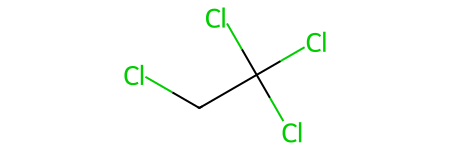

In [56]:
# Convertir el SMILES a un objeto molécula de RDKit para visualizarlo
rdkit_mol = Chem.MolFromSmiles(smiles)
rdkit_mol

In [57]:
print("Longitud del DataFrame:", len(df))

Longitud del DataFrame: 1144


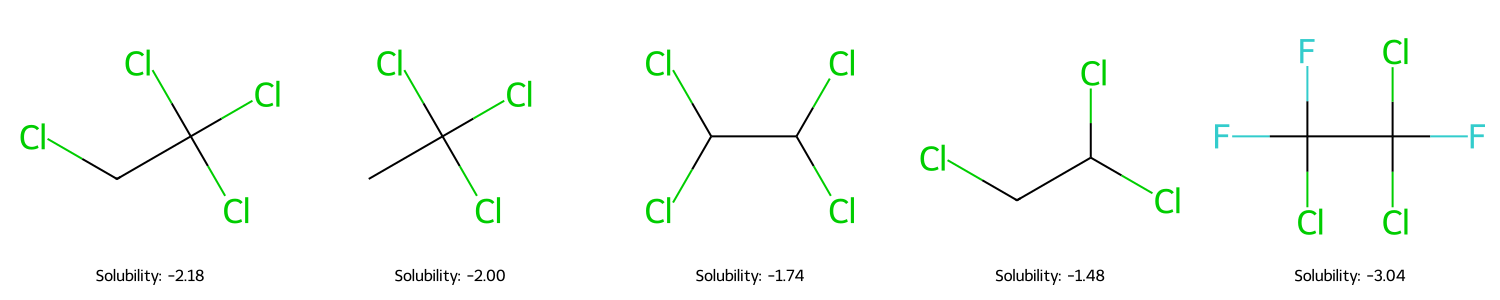

In [58]:
def visualize_molecules(df, n_molecules=6):
    # Create a list to store the molecule images
    imgs = []
    legends = []

    # TODO:
    # For each molecule in the dataset:
    # 1. Retrieve the SMILES string from the current row and store it in a variable called `smiles`.

    # 2. Retrieve the corresponding solubility value and store it in a variable called `solubility`.

    # 3. Convert the SMILES string into an RDKit molecule object using Chem and store it in a variable called `mol`.

    # Hints:
    # - Use the current index (idx) to access the DataFrame row.
    # - Identify the correct column names for SMILES and solubility.
    # - Use an RDKit function to convert SMILES → molecule object.
    
    for idx in range(min(n_molecules, len(df))):
      smiles=df['SMILES'][idx]
      mol = Chem.MolFromSmiles(smiles)
      solubility=df['measured log(solubility:mol/L)'][idx]


    # TODO (Validation):
    # Ensure that `mol` is valid (not None).If it´s not valid skip this iteration to avoid errors in later steps.
    # # YOUR CODE HERE
      if mol is None:
        continue

      AllChem.Compute2DCoords(mol) # Calcular las coordenadas en 2D (posición x, y) de cada átomo de la molécula, y las guarda dentro del propio objeto mol.

    # Append the molecule and its legend to the respective lists
      imgs.append(mol)
      legends.append(f'Solubility: {solubility:.2f}')

    # Create a grid of molecule images
    img = Draw.MolsToGridImage(
        imgs,
        legends=legends,  # Add legends with solubility values
        molsPerRow=5,  # Number of molecules per row
        subImgSize=(300, 300),  # Size of each sub-image
        returnPNG=False  # Return as an image object, not PNG
    )
    return img

# Visualize the first 5 molecules in the dataset
img = visualize_molecules(df.iloc[0:5])
img

## Molecular Descriptors

Molecular descriptors are numerical values that describe the properties of molecules. These descriptors are widely used in cheminformatics and machine learning for tasks such as property prediction, similarity analysis, and clustering.


Let´s check what is a molecule descriptor. First we need to transform SMILES into a molecule object

In [59]:
from rdkit import Chem
from rdkit.Chem import Descriptors

# Convert SMILES to RDKit mol objects
mols = [Chem.MolFromSmiles(x) for x in df['SMILES']] # Es una lista con los objetos molécula de RDKit correspondientes a cada SMILES válido
mols = [x for x in mols if x is not None]            # solo deja pasar el elemento x si no es None. Si x sí es None (es decir, ese SMILES no se pudo convertir), esa vuelta del ciclo simplemente no agrega nada a la lista nueva
df['mols'] = mols                                    # Crea una columna nueva en el dataframe llamada 'mols' que contiene los objetos molécula de RDKit correspondientes a cada SMILES válido
df.head()

,measured log(solubility:mol/L),SMILES,mols
0,-2.18,ClCC(Cl)(Cl)Cl,<rdkit.Chem.rdchem.Mol object at 0x000001CFD06...
1,-2.00,CC(Cl)(Cl)Cl,<rdkit.Chem.rdchem.Mol object at 0x000001CFD06...
2,-1.74,ClC(Cl)C(Cl)Cl,<rdkit.Chem.rdchem.Mol object at 0x000001CFD06...
3,-1.48,ClCC(Cl)Cl,<rdkit.Chem.rdchem.Mol object at 0x000001CFD06...
4,-3.04,FC(F)(Cl)C(F)(Cl)Cl,<rdkit.Chem.rdchem.Mol object at 0x000001CFD06...


### Molecular Descriptors in Our Dataset

Using RDKit, we will calculate the following molecular descriptors for the molecules in our dataset:

- **Molecular Weight (g/mol)**: The total molecular weight of the compound.
- **Octanol-Water Partition Coefficient (LogP)**: A measure of the compound's hydrophobicity.
- **Topological Polar Surface Area (TPSA)**: The surface area of polar atoms in the molecule.
- **Number of H-Bond Donors**: The count of hydrogen bond donors in the molecule.
- **Number of H-Bond Acceptors**: The count of hydrogen bond acceptors in the molecule.
- **Ring Count**: The number of rings in the molecular structure.
- **Heavy Atom Count**: The number of non-hydrogen atoms in the molecule.
- **Number of Rotatable Bonds**: The count of bonds that can freely rotate.

These descriptors provide a comprehensive representation of the physicochemical properties of the molecules in our dataset, enabling us to better understand their behavior and predict their solubility.

In [60]:
# TODO:
# Create a dictionary called `data` that contains molecular descriptors computed from the molecules in `df['mols']`.
#
# Instructions:
# - Include the SMILES strings under the key `'smiles'`.
# - Compute the following descriptors using RDKit:
#   * Molecular Weight
#   * LogP (octanol-water partition coefficient)
#   * TPSA (topological polar surface area)
#   * Number of H-bond donors
#   * Number of H-bond acceptors
#   * Ring count
#   * Heavy atom count
#   * Number of rotatable bonds
#
# Hints:
# - Use list comprehensions to iterate over `df['mols']`.
# - Use the RDKit `Descriptors` module.
# - Each descriptor should be stored as a list.


# YOUR CODE HERE

data = {
    'smiles': df['SMILES'],
    'MolWt'         : [Descriptors.MolWt(m) for m in df['mols']],
    'LogP'          : [Descriptors.MolLogP(m) for m in df['mols']],
    'TPSA'          : [ Descriptors.TPSA(m) for m in df['mols']],
    'NumHDonors'    : [ Descriptors.NumHDonors(m) for m in df['mols']],
    'NumHAcceptors' : [ Descriptors.NumHAcceptors(m) for m in df['mols']],
    'RingCount'     : [Descriptors.RingCount(m) for m in df['mols']],
    'HeavyAtomCount': [Descriptors.HeavyAtomCount(m) for m in df['mols']],
    'RotatableBonds': [Descriptors.NumRotatableBonds(m) for m in df['mols']]
}

# Se crea el DataFrame que contiene los descriptores moleculares calculados a partir de las moléculas en `df['mols']`.
mol_descriptor_df = pd.DataFrame(data)

# Agrega una columna al DataFrame `mol_descriptor_df` llamada 'Solubility' que contiene los valores de solubilidad medidos correspondientes a cada molécula en el DataFrame original `df`.
mol_descriptor_df['Solubility'] = df['measured log(solubility:mol/L)']  

# Create descriptor labels for plotting
descriptor_labels = {
    'Solubility': 'Solubility (logS)',
    'MolWt': 'Molecular Weight (g/mol)',
    'LogP': 'Octanol-Water Partition Coefficient (LogP)',
    'TPSA': 'Topological Polar Surface Area (TPSA)',
    'NumHDonors': 'Number of H-Bond Donors',
    'NumHAcceptors': 'Number of H-Bond Acceptors',
    'RingCount': 'Ring Count',
    'HeavyAtomCount': 'Heavy Atom Count',
    'RotatableBonds': 'Number of Rotatable Bonds'
}

mol_descriptor_df = mol_descriptor_df.rename(columns=descriptor_labels)

Let´s see our dataset with molecular descriptors

In [61]:
# Dataframe con los 8 descriptores moleculares y la solubilidad medida correspondiente a cada molécula
mol_descriptor_df.head()

,smiles,Molecular Weight (g/mol),Octanol-Water Partition Coefficient (LogP),Topological Polar Surface Area (TPSA),Number of H-Bond Donors,Number of H-Bond Acceptors,Ring Count,Heavy Atom Count,Number of Rotatable Bonds,Solubility (logS)
0,ClCC(Cl)(Cl)Cl,167.850,2.5954,0.0,0,0,0,6,0,-2.18
1,CC(Cl)(Cl)Cl,133.405,2.3765,0.0,0,0,0,5,0,-2.00
2,ClC(Cl)C(Cl)Cl,167.850,2.5938,0.0,0,0,0,6,1,-1.74
3,ClCC(Cl)Cl,133.405,2.0289,0.0,0,0,0,5,1,-1.48
4,FC(F)(Cl)C(F)(Cl)Cl,187.375,2.9189,0.0,0,0,0,8,1,-3.04


### Distribution of Molecular Descriptors

We can visualize the distribution of the data describing the molecules in our dataset. This will allow us to better understand the physicochemical properties of the molecules and how they are distributed within the dataset. These distributions are useful for identifying potential biases or outliers in the molecular descriptors.

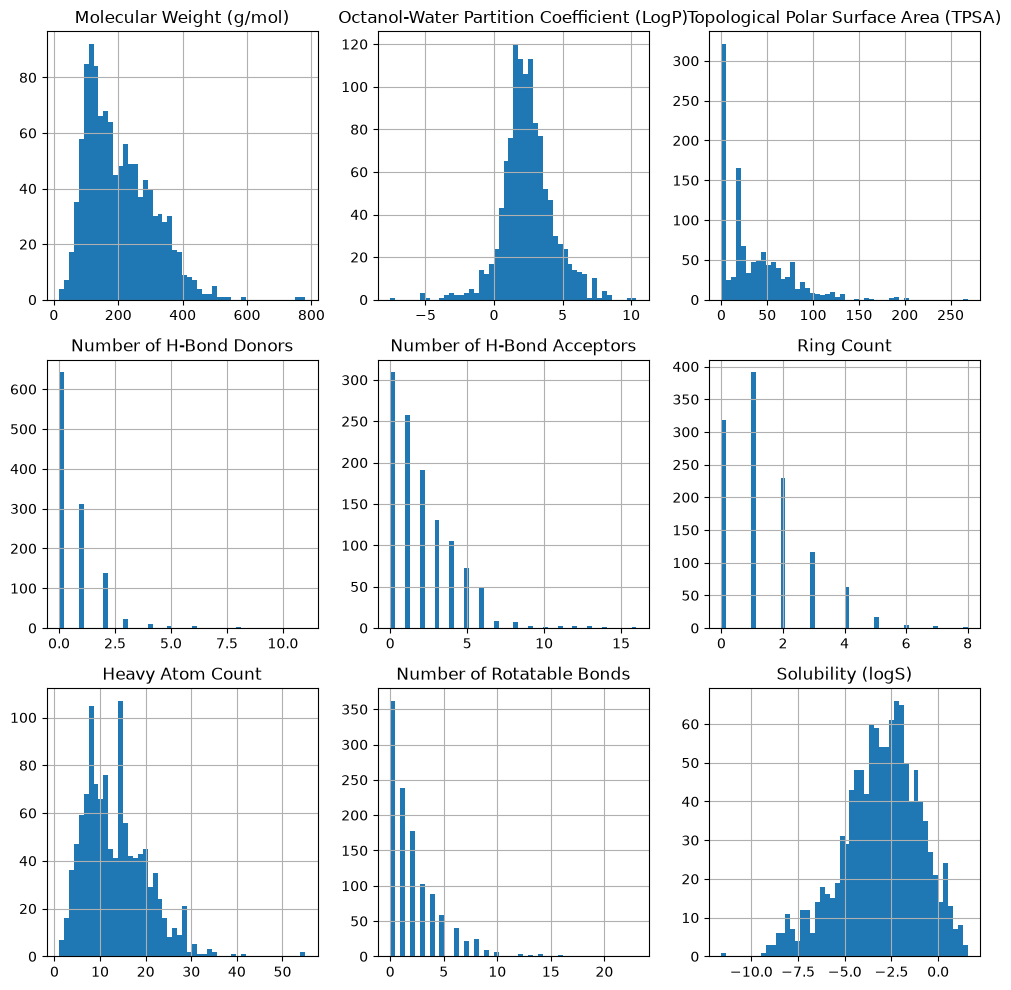

In [62]:
mol_descriptor_df1=mol_descriptor_df.drop(columns=['smiles'])
mol_descriptor_df1.hist(figsize=(10, 10), bins=50)
plt.tight_layout()
plt.show()

Some molecular descriptors are related to others. Pairplot allows us to visualize the relationships between different molecular descriptors and solubility.
This tool is useful for identifying patterns, correlations, and potential trends in the data,
which can help us better understand molecular properties of our dataset.

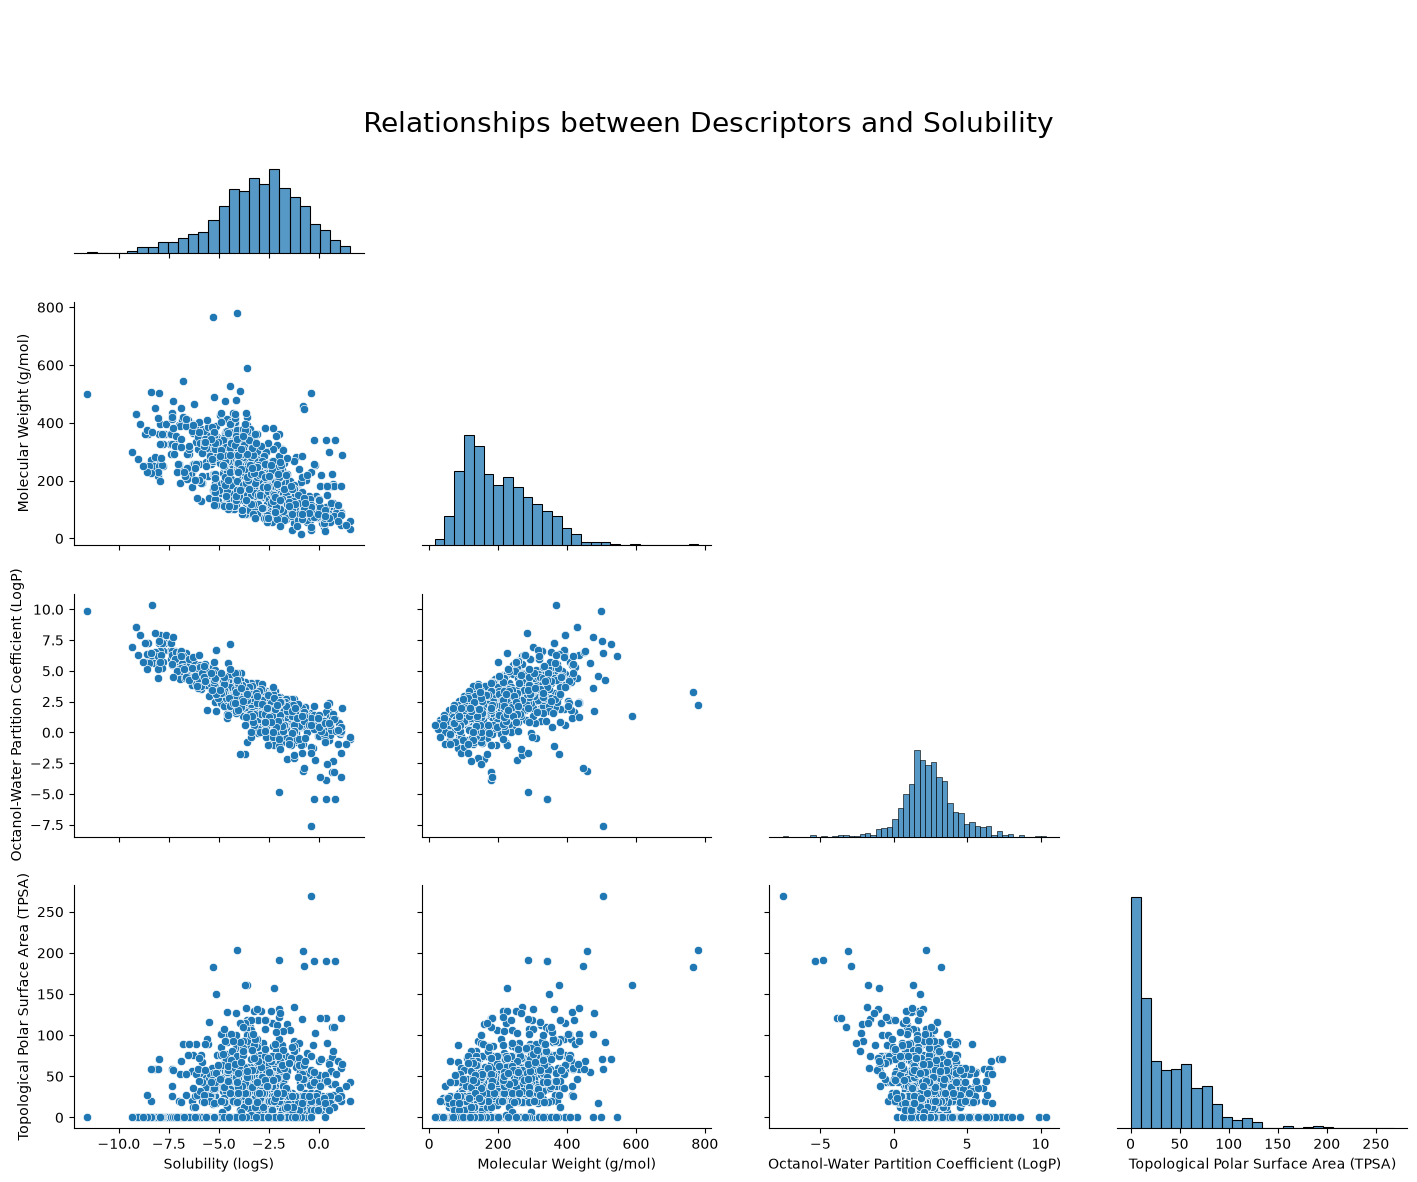

In [63]:
# Create pairplot with adjusted spacing
sns.pairplot(
    mol_descriptor_df[['Solubility (logS)', 'Molecular Weight (g/mol)',
                      'Octanol-Water Partition Coefficient (LogP)',
                      'Topological Polar Surface Area (TPSA)']],
    corner=True,
    height=3,  # Increase individual plot size
    aspect=1.2,  # Adjust aspect ratio
)

# Adjust layout
plt.subplots_adjust(
    hspace=0.2,  # Increase vertical spacing between subplots
    wspace=0.2   # Increase horizontal spacing between subplots
)

# Add title with adjusted position
plt.suptitle("Relationships between Descriptors and Solubility",
            fontsize=20,
            y=0.9)  # Move title up slightly

plt.show()


In a pairplot, it can be challenging to observe relationships when we have many variables. To simplify this, we can also create a correlation matrix.


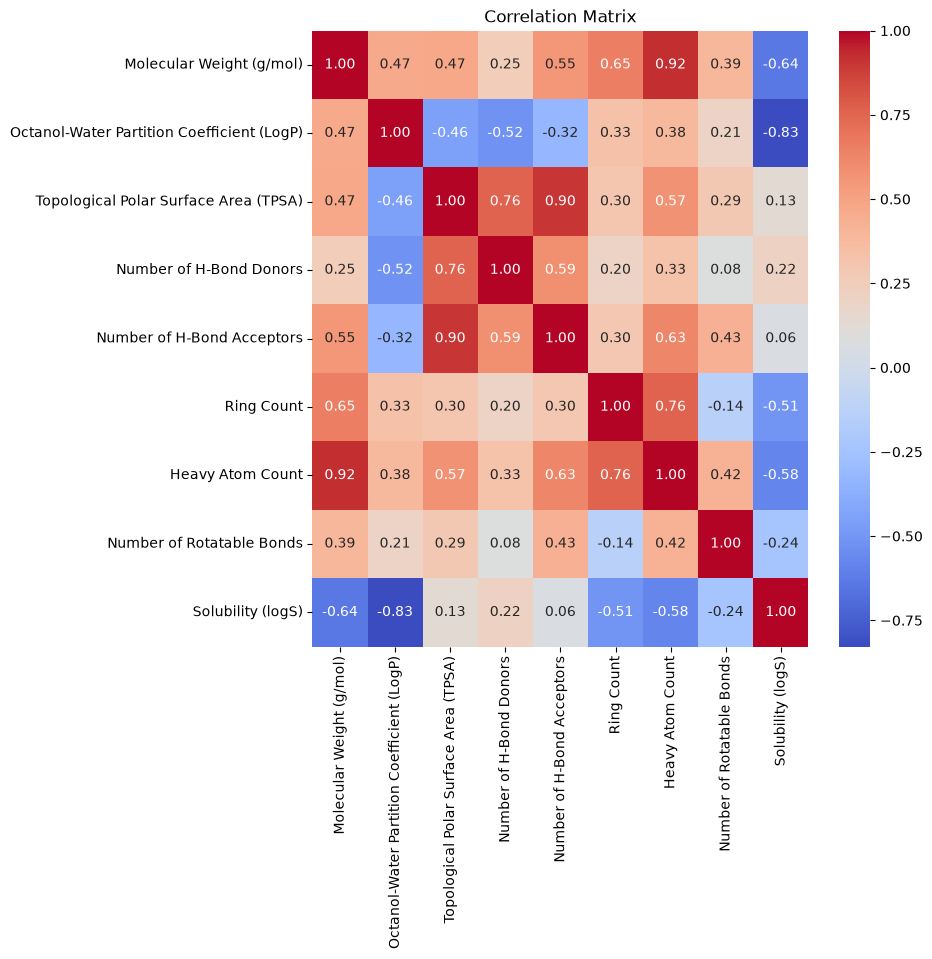

In [64]:
import numpy as np
numeric_df = mol_descriptor_df.select_dtypes(include=[np.number])

plt.figure(figsize=(8, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


Se observa de la figura las correlaciones que hay entre los descriptores. Este caso:
- Rojo intenso = correlación fuerte y positiva
- Azul intenso = correlación fuerte y negativa
- Colores pálidos/blancos = casi sin relación (cerca de 0)

El análisis de correlaciones muestra que, de los ocho descriptores moleculares calculados, el coeficiente de partición octanol-agua (LogP) es el que mejor explica la solubilidad medida, con una correlación negativa fuerte (-0.83). Las moléculas más lipofílicas tienden a ser mucho menos solubles en agua, lo cual es consistente con el comportamiento fisicoquímico esperado.

El peso molecular y el número de átomos pesados también muestran correlaciones negativas moderadas (-0.64 y -0.58 respectivamente), reflejando que las moléculas más grandes tienden a disolverse peor.

En contraste, descriptores relacionados con la polaridad de la superficie, como el TPSA y el número de aceptores de puentes de hidrógeno, muestran una relación prácticamente nula con la solubilidad en este dataset (0.13 y 0.06), por lo que se pueden decir que aportan poca información predictiva.


Let´s check the relevance molecular descriptors with Solubility

| Molecular Property                              | Correlation with logS | Interpretation / Relevance                                                                    |
|-------------------------------------------------|------------------------|-----------------------------------------------------------------------------------------------|
| Octanol-Water Partition Coefficient (LogP)      | **-0.83**              | More lipophilic molecules (higher LogP) tend to be less soluble in water.                    |
| Molecular Weight (g/mol)                        | **-0.64**              | Larger or heavier molecules are generally less water-soluble.                                |
| Heavy Atom Count                                | **-0.58**              | Molecules with more heavy atoms tend to be less soluble.                                     |
| Ring Count                                      | **-0.51**              | Molecules with more ring structures are often less soluble.                                  |
| Number of Rotatable Bonds                       | -0.24                  | Increased flexibility might reduce solubility in this dataset.                               |
| Number of H-Bond Donors                         | 0.22                   | More hydrogen bond donors can slightly increase solubility.                                  |
| Topological Polar Surface Area (TPSA)           | 0.13                   | Polar surface area may improve solubility, but has low correlation here.                    |
| Number of H-Bond Acceptors                      | 0.07                   | Very weak influence on solubility in this dataset.                                            |

📌 Conclusion

The molecular properties most strongly (negatively) correlated with solubility are:

- LogP (lipophilicity)
- Molecular Weight
- Heavy Atom Count
- Ring Count

These features stand out as the most predictive variables for solubility in this dataset, and are key candidates for use in predictive models or molecular design pipelines.


That's a lot of features, isn't it? How can we pass all this information to the deep learning model? In the field of cheminformatics, there are already libraries that help us create **embeddings** that encapsulate this information. For this, we will use **DeepChem**.

A **Featurizer** is a piece of code that transforms raw input data into a processed form suitable for machine learning.


In [65]:
from deepchem.feat import RDKitDescriptors


smiles_mols = df['SMILES'].values
solubility = df['measured log(solubility:mol/L)'].values

# TODO:
# Initialize an RDKit descriptor featurizer from DeepChem and generate molecular features.
#
# Instructions:
# - Create an instance of `RDKitDescriptors`.
# - Use it to featurize the SMILES strings.
# - Store the result in a variable called `mol_features`.

# YOUR CODE HERE
featurizer = RDKitDescriptors()
mol_features = featurizer.featurize(smiles_mols)

In [66]:
# Es el número de funciones de cálculo de descriptores trae integradas la versión instalada de RDKit. 
# Antes eran 8, ahora son 217 generados automáticamente por el featurizer de DeepChem

print(f"Number of molecules: {mol_features.shape[1]}")
mol_features = mol_features[:, ~np.isnan(mol_features).any(axis=0)]
print(f"Number of molecular descriptors without invalid values: {mol_features.shape[1]}")

Number of molecules: 217
Number of molecular descriptors without invalid values: 217


In [67]:
print("valores de cada uno de esos 217 descriptores, calculados para cada una de las 1144 moléculas:")
mol_features


valores de cada uno de esos 217 descriptores, calculados para cada una de las 1144 moléculas:


array([[ 1.35164412,  2.15541599, -2.00351466, ...,  0.        ,
         0.        ,  0.48713771],
       [ 0.72192809,  2.06564122, -1.94269043, ...,  0.        ,
         0.        ,  0.44517056],
       [ 1.36096405,  2.06377539, -1.94592998, ...,  0.        ,
         0.        ,  0.52731169],
       ...,
       [ 2.54189484,  2.25167752, -2.16919854, ...,  0.        ,
         0.        ,  0.74762581],
       [ 2.41022225,  2.20704877, -2.12938706, ...,  0.        ,
         0.        ,  0.78627512],
       [ 2.01652651,  2.01134734, -2.04622586, ...,  0.        ,
         0.        ,  0.7158371 ]], shape=(1144, 217))

Now check the data we will work with: solubility and embeding of molecular descriptors

In [68]:
# Imprimir los descriptores
nombres_descriptores = list(featurizer.reqd_properties.keys())
print(len(nombres_descriptores))
print(nombres_descriptores)

217
['AvgIpc', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'EState_VSA1', 'EState_VSA10', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'EState_VSA5', 'EState_VSA6', 'EState_VSA7', 'EState_VSA8', 'EState_VSA9', 'ExactMolWt', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'FractionCSP3', 'HallKierAlpha', 'HeavyAtomCount', 'HeavyAtomMolWt', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'MaxAbsEStateIndex', 'MaxAbsPartialCharge', 'MaxEStateIndex', 'MaxPartialCharge', 'MinAbsEStateIndex', 'MinAbsPartialCharge', 'MinEStateIndex', 'MinPartialCharge', 'MolLogP', 'MolMR', 'MolWt', 'NHOHCount', 'NOCount', 'NumAliphaticCarbocycles', 'NumAliphaticHeterocycles', 'NumAliphaticRings', 'NumAmideBonds', 'NumAromaticCarbocycles', 'NumAromaticHeterocycles', 'Num

In [69]:
df['molecular features'] = list(mol_features)    # Agregar una columna. Cada celda contiene todo un vector de 217 números, los cuales son los descriptores
df.drop(columns=['mols','SMILES'], inplace=True) # Eliminar las columnas originales de mols y SMILES
df.head()

,measured log(solubility:mol/L),molecular features
0,-2.18,"[1.3516441151533922, 2.15541598973672, -2.0035..."
1,-2.00,"[0.7219280948873623, 2.065641219022883, -1.942..."
2,-1.74,"[1.3609640474436813, 2.063775394098705, -1.945..."
3,-1.48,"[1.3787834934861756, 1.8823546186514333, -1.82..."
4,-3.04,"[1.253297578463043, 2.5067376054930928, -2.131..."


## Data Splitting
When developing Deep Learning models, it's crucial to properly split our data to ensure robust evaluation and prevent overfitting. The data is divided into three distinct sets:

### Train/Validation/Test Split
We split our data into three sets with the following distribution:

- **Training Set (80%)**
  - Used to train the model
  - The model learns patterns from this data
  - Weights and biases are adjusted based on this set

- **Validation Set (10%)**
  - Used to tune hyperparameters
  - Helps detect overfitting during training
  - Not used for training, only for evaluation
  - Guides model selection and hyperparameter optimization

- **Test Set (10%)**
  - Used only for final evaluation
  - Never seen during training or tuning
  - Provides unbiased estimate of model performance
  - Simulates real-world performance

### Why Split the Data?
1. **Prevent Overfitting**
   - Keeping test data separate ensures we don't tune our model to specific examples
   - Helps evaluate true generalization ability

2. **Proper Evaluation**
   - Test set provides unbiased performance metrics
   - Validation set helps optimize model without contaminating test data

3. **Model Selection**
   - Validation performance guides architecture and hyperparameter choices
   - Helps choose between different model variants

![Train-Validation-Test Split](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)

This splitting strategy is fundamental for developing robust Deep Learning models that can generalize well to new, unseen data.

In [71]:
from deepchem.splits import RandomSplitter
from deepchem.data import NumpyDataset

# Prepare the data
X = np.array([x for x in df['molecular features']])  # Features
y = df['measured log(solubility:mol/L)'].values.reshape(-1, 1)  # Target reshaped for correct format

# Create the DeepChem dataset
dataset = NumpyDataset(X=X, y=y)

# Use the splitter
# TODO:
# Split the dataset into training, validation, and test sets.
#
# Instructions:
# - Use `RandomSplitter` from DeepChem.
# - Split the dataset into:
#   * 80% training
#   * 10% validation
#   * 10% test
# - Use a fixed random seed for reproducibility.
#
# Hints:
# - Use `.train_valid_test_split()` method.

# YOUR CODE HERE
splitter = RandomSplitter()
train_dataset, valid_dataset, test_dataset = splitter.train_valid_test_split(
    dataset,
    frac_train=0.8,
    frac_valid=0.1,
    frac_test=0.1,
    seed=42
)
# Check the dimensions
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(valid_dataset)}")
print(f"Test set size: {len(test_dataset)}")


Training set size: 915
Validation set size: 114
Test set size: 115


# 3. Neural Network Architecture

### Understanding Neural Network Layers

A neural network consists of three main types of layers:

1. **Input Layer**
   - First layer in the network
   - Receives raw features (in our case, molecular descriptors)
   - Number of neurons equals number of input features
   - No computation performed, just passes data forward

2. **Hidden Layers**
   - Layers between input and output
   - Process and transform the data
   - Apply weights, biases, and activation functions
   - Can be multiple layers deep
   - Each neuron connects to all neurons in next layer

3. **Output Layer**
   - Final layer of the network
   - Produces the prediction (in our case, solubility value)
   - Number of neurons matches prediction task
   - One neuron for regression (our case)

<div align="center">
<img src="https://github.com/schwallergroup/ai4chem_course/blob/main/notebooks/03%20-%20Intro%20to%20Deep%20Learning/img/nn_image.png?raw=1" width="500"/>
</div>

### Understanding Layer Depth in Neural Networks
The number of hidden layers significantly impacts a neural network's ability to learn complex, non-linear patterns:

1. **Single Layer Networks**
   - Can only learn linear relationships
   - Limited capacity for complex patterns
   - Example: `y = ax + b`

2. **Two Layer Networks**
   - Can approximate any continuous function
   - Good for simple non-linear patterns
   - Example: Can learn basic curves and patterns

3. **Deep Networks (3+ layers)**
   - Can learn hierarchical features
   - Better at capturing complex non-linear relationships
   - More efficient parameter usage for complex tasks

<div align="center">
<img src="https://vitalflux.com/wp-content/uploads/2022/04/Linearly-vs-Not-linearly-separable-datasets-768x285.png" width="600"/>
</div>

### Our Implementation
We'll experiment with different architectures using grid search:

```python
param_grid = {
    'num_layers': [1, 2, 3],     
    'hidden_size': [256, 512],   
    'learning_rate': [0.001, 0.0001],
    'batch_size': [32, 64]
}
```

### Expected Impact:
- **More Layers**: Better capture of complex molecular relationships
- **More Neurons**: Increased model capacity but risk of overfitting
- **Trade-off**: Deeper networks might be harder to train but could learn better representations

### Why This Matters for Solubility Prediction
Molecular solubility depends on multiple non-linear interactions:
- Hydrogen bonding
- Van der Waals forces
- Conformational changes
- Complex structure-property relationships

A deeper network might better capture these intricate relationships between molecular features and solubility.

## 3.1 Creating a Deep Learning Model

Modern deep learning frameworks like [PyTorch Lightning](https://pytorch-lightning.readthedocs.io/en/stable/index.html) use object-oriented programming to make model creation intuitive and flexible. Before we build our neural network, let's understand the fundamental concept of classes.

### Understanding Classes in Python

A class is like a blueprint that defines:
- What properties (attributes) an object has
- What actions (methods) it can perform

Think of it this way:
- A class is to an object what a blueprint is to a house
- Many houses can be built from the same blueprint
- Each house (instance) can have different:
  - Number of rooms
  - Size
  - Color
  - Utilities

Here's a simple example:

```python
class House:
    def __init__(self, rooms, size, style):
        # Attributes
        self.rooms = rooms    # Like layers in our network
        self.size = size      # Like neurons in each layer
        self.style = style    # Like activation function
        
    def describe(self):
        # Method - what the house can do
        print(f"This {self.style} house has {self.rooms} rooms and is {self.size} sqft")
```

We can create multiple houses (instances) from this class:
```python
    modern_house = House(rooms=3, size=2000, style="modern")
    colonial_house = House(rooms=5, size=3000, style="colonial")

    modern_house.describe()
```
The output should be something like this: ```"This modern house has 3 rooms and is 2000 sqft"```


### From Houses to Neural Networks
Now let's define a NeuralNetwork class.This same concept applies to creating neural networks, a neural network class defines its structure and behavior. Here's how the analogy translates:

| House Blueprint | Neural Network |
|----------------|----------------|
| Rooms | Layers |
| Size | Number of Neurons |
| Style | Activation Functions |
| Description | Predictions |

#### Neural Network Components


### 1. Attributes
- **Learning Rate (`lr`)**:
  - Controls weight update magnitude
  - Default: 1e-3

- **Datasets**:
  - `train_dataset`: Training data
  - `valid_dataset`: Validation data  
  - `test_dataset`: Test data

- **Batch Size**:
  - Number of samples per update
  - Default: 254

- **Loss Tracking**:
  - `train_losses`: Average loss per epoch
  - `val_losses`: Validation loss per epoch
  - `train_epoch_losses`: Individual batch losses
  - `val_epoch_losses`: Individual validation losses

- **Model Architecture**:
  - Input layer: `input_sz` features
  - Hidden layers: `num_layers` with `hidden_sz` neurons
  - Output layer: Single neuron (regression)
  - Activation: ReLU between layers

### 2. Methods
- **Forward Pass (`forward`)**:
  - Takes input tensor x
  - Passes through model layers
  - Returns flattened predictions

- **Training (`training_step`)**:
  - Processes batch of data
  - Computes predictions and loss
  - Logs training metrics
  - Stores loss for learning curves

- **Validation (`validation_step`)**:
  - Evaluates model on validation data
  - Computes validation loss
  - No weight updates
  - Tracks performance

- **Testing (`test_step`)**:
  - Final model evaluation
  - Computes test MSE
  - No weight updates

- **Optimization (`configure_optimizers`)**:
  - Uses Adam optimizer
  - Configurable learning rate

- **Data Loading**:
  - `train_dataloader`: Training data with shuffling
  - `val_dataloader`: Validation data, no shuffle
  - `test_dataloader`: Test data, no shuffle

In [72]:
import os
import torch
import wandb
from torch import nn
import torch.nn.functional as F
import pytorch_lightning as pl
from torch.utils.data import DataLoader
from pytorch_lightning.loggers import WandbLogger
from torch.utils.data import TensorDataset

In [73]:
class NeuralNetwork(pl.LightningModule):
    """
    Neural network model for molecular solubility prediction using PyTorch Lightning.

    Attributes:
        lr (float): Learning rate for optimizer (default: 1e-3)
        train_dataset: Training dataset with molecular features and solubility values
        valid_dataset: Validation dataset
        test_dataset: Test dataset
        batch_size (int): Number of samples per batch (default: 254)
        train_losses (list): Track average loss per epoch during training
        val_losses (list): Track average loss per epoch during validation
        train_epoch_losses (list): Store individual batch losses within an epoch
        val_epoch_losses (list): Store individual validation losses within an epoch
        model (nn.Sequential): Neural network architecture constructed dynamically

    Architecture:
        - Input Layer: Takes molecular descriptors (input_sz features)
        - Hidden Layers: num_layers with hidden_sz neurons each
        - ReLU activation between layers
        - Output Layer: Single neuron for solubility prediction
    """
    def __init__(self, input_sz, hidden_sz, num_layers, train_dataset, valid_dataset, test_dataset, batch_size=254, lr=1e-3):
        """
        Initialize model architecture and training parameters.

        Args:
            input_sz (int): Number of input features (molecular descriptors)
            hidden_sz (int): Number of neurons in hidden layers
            num_layers (int): Number of hidden layers
            train_dataset: Training data
            valid_dataset: Validation data
            test_dataset: Test data
            batch_size (int): Samples per batch (default: 254)
            lr (float): Learning rate (default: 1e-3)
        """
        super().__init__()
        self.lr = lr  # Learning rate
        self.train_dataset = train_dataset  # Training dataset
        self.valid_dataset = valid_dataset  # Validation dataset
        self.test_dataset = test_dataset  # Test dataset
        self.batch_size = batch_size  # Batch size for data loaders

        # Initialize lists to store losses for training and validation
        self.train_losses = []
        self.val_losses = []
        self.train_epoch_losses = []
        self.val_epoch_losses = []

        # Dynamically construct the neural network based on num_layers
        # TODO:
        # Build the neural network architecture dynamically.
        #
        # Instructions:
        # - Create a list called `layers`.
        # - Add an input layer that maps from `input_sz` to `hidden_sz`.
        # - Add a ReLU activation.
        # - Add additional hidden layers based on `num_layers`.
        # - Add a final output layer with a single neuron.
        #
        # Hints:
        # - Use `nn.Linear` for fully connected layers.
        # - Use `nn.ReLU` for activation.
        # - The output layer should map to 1 value (regression task).

        # YOUR CODE HERE
        layers =  []
        # Creación de la capa de entrada
        layers.append(nn.Linear(input_sz, hidden_sz))  # creación de la capa de entrada 
        layers.append(nn.ReLU())                       # agrega la función de activación ReLU
        
        # Crear n capas ocultas 
        for _ in range(num_layers):                    # Añadir n capas ocultas
            layers.append(nn.Linear(hidden_sz, hidden_sz))
            layers.append(nn.ReLU())
        
        # Crear capa de salida con una neurona
        layers.append(nn.Linear(hidden_sz, 1))
         
        # Create the model as a sequential container
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        """
        Forward pass through the network.

        Args:
            x (torch.Tensor): Input tensor. Entra un vector de 217 descriptores por molécula

        Returns:
            torch.Tensor: Predicted solubility values (flattened)
        """
        return self.model(x).flatten()  #  Al llamar self.model, PyTorch pasa automáticamente x por cada una de las capas de la arquitectura
                                        #  Devuelve un tensor 1D de tamaño (batch_size,): una predicción de solubilidad (1 número) por cada molécula de entrada
    def training_step(self, batch, batch_idx):
        """
        Execute single training step on one batch.

        Args:
            batch (tuple): Batch of (features, targets)
            batch_idx (int): Index of current batch

        Returns:
            torch.Tensor: Computed MSE loss
        """
        x, y = batch                                                # Unpack features and targets: 
                                                                    #x: los descriptores de las 254 moléculas elegidas para este batch, apiladas como filas.
                                                                    #y: las solubilidades reales de esas mismas 254 moléculas, en el mismo orden que x_batch
                                                                    
        z = self.model(x)                                           # Forward pass
        loss = F.mse_loss(z, y)                                     # Compute mean squared error loss J
        self.log("Train loss", loss, on_epoch=True, prog_bar=True)  # Log training loss

        # Store the loss for training curve visualization
        self.train_epoch_losses.append(loss.detach())
        return loss

    def validation_step(self, batch, batch_idx):
        """
        Execute single validation step.

        Args:
            batch (tuple): Batch of (features, targets)
            batch_idx (int): Index of current batch

        Returns:
            torch.Tensor: Computed validation MSE loss
        """
        x, y = batch             # Unpack features and targets
        z = self.model(x)        # Forward pass
        loss = F.mse_loss(z, y)  # Compute mean squared error loss
        self.log("Valid MSE", loss, on_epoch=True, prog_bar=True)  # Log validation loss
    

        # Store the loss for validation curve visualization
        self.val_epoch_losses.append(loss.detach())
        return loss

    def test_step(self, batch, batch_idx):
        """
        Execute single test step.

        Args:
            batch (tuple): Batch of (features, targets)
            batch_idx (int): Index of current batch
        """
        x, y = batch  # Unpack features and targets
        z = self.model(x)  # Forward pass
        loss = F.mse_loss(z, y)  # Compute mean squared error loss
        self.log("Test MSE", loss)  # Log test loss

    def configure_optimizers(self):
        """
        Configure optimizer for training.

        Returns:
            torch.optim.Optimizer: Adam optimizer with specified learning rate
        """
        return torch.optim.Adam(self.parameters(), lr=self.lr)

    def train_dataloader(self):
        """
        Create training data loader.

        Returns:
            DataLoader: Training data loader with shuffling enabled
        """
        X = torch.FloatTensor(self.train_dataset.X)  # Convert features to tensor
        y = torch.FloatTensor(self.train_dataset.y)  # Convert targets to tensor
        return DataLoader(
            TensorDataset(X, y),
            batch_size=self.batch_size,
            shuffle=True  # Shuffle data for training
        )

    def val_dataloader(self):
        """
        Create validation data loader.

        Returns:
            DataLoader: Validation data loader
        """
        X = torch.FloatTensor(self.valid_dataset.X)  # Convert features to tensor
        y = torch.FloatTensor(self.valid_dataset.y)  # Convert targets to tensor
        return DataLoader(
            TensorDataset(X, y),
            batch_size=self.batch_size,
            shuffle=True  # Shuffle data for validation
        )

    def test_dataloader(self):
        """
        Create test data loader.

        Returns:
            DataLoader: Test data loader
        """
        X = torch.FloatTensor(self.test_dataset.X)  # Convert features to tensor
        y = torch.FloatTensor(self.test_dataset.y)  # Convert targets to tensor
        return DataLoader(
            TensorDataset(X, y),
            batch_size=self.batch_size,
            shuffle=True  # Shuffle data for testing
        )

    def on_train_epoch_end(self):
        """
        Calculate and save the average training loss at the end of each epoch.
        Clears the list of batch losses for the current epoch to prepare for the next epoch.
        """
        avg_loss = torch.stack(self.train_epoch_losses).mean()  # Compute average loss for the epoch
        self.train_losses.append(avg_loss.item())  # Append the average loss to the training losses list
        self.train_epoch_losses.clear()  # Clear the batch losses for the current epoch

    def on_validation_epoch_end(self):
        """
        Calculate and save the average validation loss at the end of each epoch.
        Clears the list of batch losses for the current epoch to prepare for the next epoch.
        """
        avg_loss = torch.stack(self.val_epoch_losses).mean()  # Compute average loss for the epoch
        self.val_losses.append(avg_loss.item())  # Append the average loss to the validation losses list
        self.val_epoch_losses.clear()  # Clear the batch losses for the current epoch

## PyTorch Lightning Trainer

The Trainer is a high-level interface that handles:
1. Training loop management
2. Validation checks
3. Early stopping
4. GPU acceleration
5. Logging and monitoring

Let's implement grid search to find optimal hyperparameters:

### Hyperparameters Explained

1. **Learning Rate (lr)**:
   - Controls how much we adjust weights in each step
   - Too high: unstable training
   - Too low: slow training

2. **Batch Size**:
   - Number of samples processed before weight update
   - Larger: more stable, but needs more memory
   - Smaller: more noise, but can help escape local minima

3. **Hidden Size**:
   - Number of neurons in hidden layers
   - Larger: more capacity to learn, but risk of overfitting
   - Smaller: may underfit if too small

4. **Number of Epochs**:
   - How many times we go through the entire dataset
   - Too few: underfitting
   - Too many: risk of overfitting

### Root Mean Square Error (RMSE)
RMSE is our main evaluation metric:
- Calculated as: √(mean((predicted - actual)²))
- Gives more weight to larger errors
- In same units as our target (log mol/L)


### ¿Por qué Grid Search si ya usamos Adam? 

Aunque ambos parecen “ajustar” el learning rate, actúan en momentos distintos.

Adam opera durante el entrenamiento, adaptando automáticamente el tamaño de paso de cada peso según el historial de gradientes, pero siempre partiendo de un lr base fijado de antemano, y no tiene ninguna influencia sobre decisiones de arquitectura como hidden_size, num_layers o batch_size. 

Grid Search opera antes, por fuera: prueba distintas combinaciones completas de configuración (incluido ese lr inicial) y compara entrenamientos completos para elegir la mejor; en otras palabras, Grid Search decide con qué configuración arranca cada entrenamiento, y Adam es quien, ya dentro de ese entrenamiento, ajusta el paso sobre la marcha.

In [74]:
def grid_search_cv(param_grid):
    best_rmse = float('inf')
    best_params = None
    results = []

    for lr in param_grid['learning_rate']:
        for hidden_size in param_grid['hidden_size']:
            for batch_size in param_grid['batch_size']:
                for num_layers in param_grid['num_layers']:
                    print(f'\nTesting: lr={lr}, hidden_size={hidden_size}, batch_size={batch_size}, num_layers={num_layers}')

                    model = NeuralNetwork(
                        input_sz=len(train_dataset.X[1]),
                        hidden_sz=hidden_size,
                        num_layers=num_layers,
                        train_dataset=train_dataset,
                        valid_dataset=valid_dataset,
                        test_dataset=test_dataset,
                        lr=lr,
                        batch_size=batch_size
                    )

                    trainer = pl.Trainer(
                        max_epochs=50,
                        logger=False,
                        enable_progress_bar=True
                    )

                    trainer.fit(model)
                    test_results = trainer.test(ckpt_path="best")[0]
                    current_rmse = test_results["Test MSE"] ** 0.5

                    results.append({
                        'lr': lr,
                        'hidden_size': hidden_size,
                        'batch_size': batch_size,
                        'num_layers': num_layers,
                        'rmse': current_rmse
                    })

                    if current_rmse < best_rmse:
                        best_rmse = current_rmse
                        best_params = {
                            'lr': lr,
                            'hidden_size': hidden_size,
                            'batch_size': batch_size,
                            'num_layers': num_layers
                        }



    return pd.DataFrame(results), best_params


# TODO:
# Experiment with different hyperparameter values for the neural network.
# Define a dictionary called `param_grid` containing the hyperparameters to explore.
#
# Instructions:
# - The dictionary should include the following keys:
#   * 'learning_rate'
#   * 'hidden_size'
#   * 'batch_size'
#   * 'num_layers'
#
# - Each key should map to a list of values to try during grid search.
# - Modify the values inside `param_grid` to explore different configurations.
# - Try changing:
#   * Learning rate (e.g., 1e-2, 1e-3, 1e-4)
#   * Hidden layer size (e.g., 128, 256, 512)
#   * Batch size (e.g., 16, 32, 64)
#   * Number of layers (e.g., 1, 2, 3)
#
# Goal:
# - Identify which combination of hyperparameters gives the lowest RMSE.
#
# Tip:
# - Start with small grids to reduce training time.

param_grid = {
    'learning_rate': [1e-3],
    'hidden_size': [128, 256],
    'batch_size': [32],
    'num_layers': [1, 2]
}

# Run the grid search with the defined parameter grid
results_df, best_params = grid_search_cv(param_grid)

# Display the results of the grid search
print('\nGrid Search Results:')
print(results_df.sort_values('rmse'))  # Sort results by RMSE
print('\nBest parameters:')
print(best_params)  # Print the best hyperparameter configuration


Testing: lr=0.001, hidden_size=128, batch_size=32, num_layers=1


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │ 44.5 K │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 44.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 44.5 K                                                                                               
Total estimated model params size (MB): 0.178                                                                      
Modules in train mode: 6                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

c:\CCA\005_CCA_Estudiantes\Laboratorios\01_LabPatronesAgente\Tools\.venv\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

Trainable params: 187 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 187 K                                                                                                
Total estimated model params size (MB): 0.751                                                                      
Modules in train mode: 8                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=50` reached.


Restoring states from the checkpoint path at c:\CCA\005_CCA_Estudiantes\Laboratorios\checkpoints\epoch=49-step=1450-v3.ckpt
Loaded model weights from the checkpoint at c:\CCA\005_CCA_Estudiantes\Laboratorios\checkpoints\epoch=49-step=1450-v3.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         Test MSE          │    0.3393431007862091     │
└───────────────────────────┴───────────────────────────┘


Grid Search Results:
      lr  hidden_size  batch_size  num_layers      rmse
3  0.001          256          32           2  0.582532
2  0.001          256          32           1  0.617130
1  0.001          128          32           2  0.663353
0  0.001          128          32           1  0.718516

Best parameters:
{'lr': 0.001, 'hidden_size': 256, 'batch_size': 32, 'num_layers': 2}


# Reflection / Discussion:
- Which hyperparameter combination gave you the best RMSE?
- How did your choice of hyperparameter ranges affect the results?
- If you had more computational time, how would you expand your search?

# Class activity:
- Share your `param_grid` and best results with the class.
- Compare strategies: who explored wider vs. more focused ranges?

### Which hyperparameter combination gave you the best RMSE?
La combinación de hidden_size=256, num_layers=2 (con lr=0.001, batch_size=32 fijos) dio el RMSE más bajo, ≈0.58 durante el test set.

### How did your choice of hyperparameter ranges affect the results?
En este caso se dejaron fijos learning_rate y batch_size, variando solo hidden_size (128 vs 256 neuronas por capa) y num_layers (1 vs 2). Dentro de ese rango, el error disminuyó a medida que se aumentó la capacidad del modelo (más neuronas, más capas), sin llegar a un punto donde volviera a subir por overfitting. Esto sugiere que este rango se queda un poco corto: el “mejor” resultado (hidden_size=256, num_layers=2) es el mejor entre las opciones, pero no necesariamente el óptimo global.

### If you had more computational time, how would you expand your search?

Se agregarían más valores de hidden_size, por ejemplo 512, 1024, para ver si el error sigue bajando o finalmente empieza a subir por overfitting, más opciones de num_layers (3, 4), y además se variaría learning_rate y batch_size, los cuales hasta ahora son fijos. También corregiría el grid search para que la selección de la mejor combinación se haga con el validation set en vez del test set, dejando el test set solo para la evaluación final del modelo ya elegido. Y con un grid más grande, consideraría usar random search o búsqueda bayesiana en vez de grid search exhaustivo, ya que el número de combinaciones crece muy rápido con cada hiperparámetro nuevo.


## Training with Best Parameters

Now let's train our final model with the best parameters found:

In [76]:
# Añadir semilla fija
import random
torch.manual_seed(0)
torch.cuda.manual_seed(0)
np.random.seed(0)
random.seed(0)

# Create final model with best parameters
final_model = NeuralNetwork(
    input_sz=len(train_dataset.X[1]),
    hidden_sz=best_params['hidden_size'],
    num_layers=best_params['num_layers'],
    train_dataset=train_dataset,
    valid_dataset=valid_dataset,
    test_dataset=test_dataset,
    lr=best_params['lr'],
    batch_size=best_params['batch_size']
)

# Train final model
trainer = pl.Trainer(
    max_epochs=50, # Antes habían 150
    logger=False,
    enable_progress_bar=True
)

trainer.fit(final_model)
final_results = trainer.test(ckpt_path="best")

# Calculate and display final RMSE
final_rmse = final_results[0]["Test MSE"] ** 0.5
print(f'\nFinal Model RMSE: {final_rmse:.4f}')

print("\n✓ Training completed!")
print(f"  Learning Rate: {best_params['lr']}")
print(f"  Hidden Size: {best_params['hidden_size']}")
print(f"  Batch Size: {best_params['batch_size']}")
print(f"  Num Layers: {best_params['num_layers']}")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │  187 K │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 187 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 187 K                                                                                                
Total estimated model params size (MB): 0.751                                                                      
Modules in train mode: 8                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=50` reached.


Restoring states from the checkpoint path at c:\CCA\005_CCA_Estudiantes\Laboratorios\checkpoints\epoch=49-step=1450-v4.ckpt
Loaded model weights from the checkpoint at c:\CCA\005_CCA_Estudiantes\Laboratorios\checkpoints\epoch=49-step=1450-v4.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         Test MSE          │    0.4587385654449463     │
└───────────────────────────┴───────────────────────────┘


Final Model RMSE: 0.6773

✓ Training completed!
  Learning Rate: 0.001
  Hidden Size: 256
  Batch Size: 32
  Num Layers: 2


### Algunas observaciones

Inicialmente, este modelo se entrenó con max_epochs=150 (en vez de las 50 épocas usadas durante el grid search), lo que llevó a un RMSE de 0.72  más alto que el 0.58 obtenido para esta misma combinación de hiperparámetros durante la búsqueda, probablemente por sobreajuste al entrenar por más tiempo del necesario. Al corregir max_epochs a 50 (igualando el presupuesto de entrenamiento del grid search) y fijar una semilla aleatoria para reproducibilidad, el RMSE final bajó a 0.6773. Este valor sigue sin ser idéntico al observado en el grid search, lo cual es esperado, pues al no ser convexa la función de pérdida de una red neuronal, distintas inicializaciones aleatorias de los pesos pueden converger a mínimos locales ligeramente distintos, incluso con los mismos hiperparámetros y número de épocas. Aun así, 0.6773 es un valor consistente y razonable, que se toma como el resultado final del modelo.

## 5.Model Analysis

Let's analyze our model's performance through different visualizations:

### 5.1 Learning Curves
The training and validation loss curves help us understand how the model learned over time:

- **Training Loss**: Shows how well the model fits the training data
- **Validation Loss**: Indicates how well the model generalizes to unseen data

A good model should show:
- Decreasing losses over time
- Small gap between training and validation curves
- No significant oscillations
- Signs of convergence

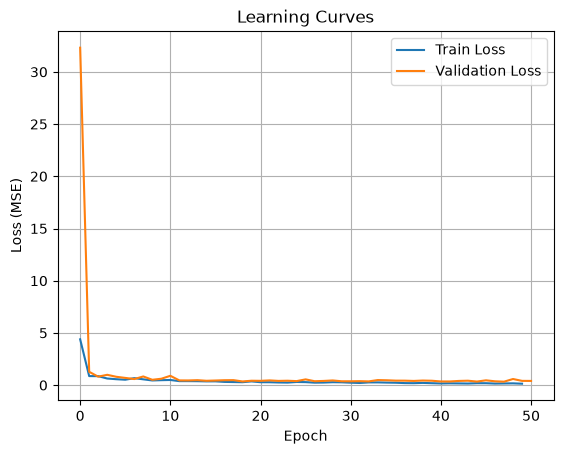

In [77]:
import matplotlib.pyplot as plt

plt.plot(final_model.train_losses, label='Train Loss')
plt.plot(final_model.val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Learning Curves')
plt.legend()
plt.grid(True)
plt.show()


### 5.2 Prediction Performance Analysis

Let's evaluate how well our model performs on the test set by comparing predicted vs actual solubility values. We'll analyze:

1. **Scatter Plot**:
   - Visual representation of predictions against actual values
   - Perfect predictions would lie on the diagonal line
   - Points above the line indicate overestimation
   - Points below the line indicate underestimation


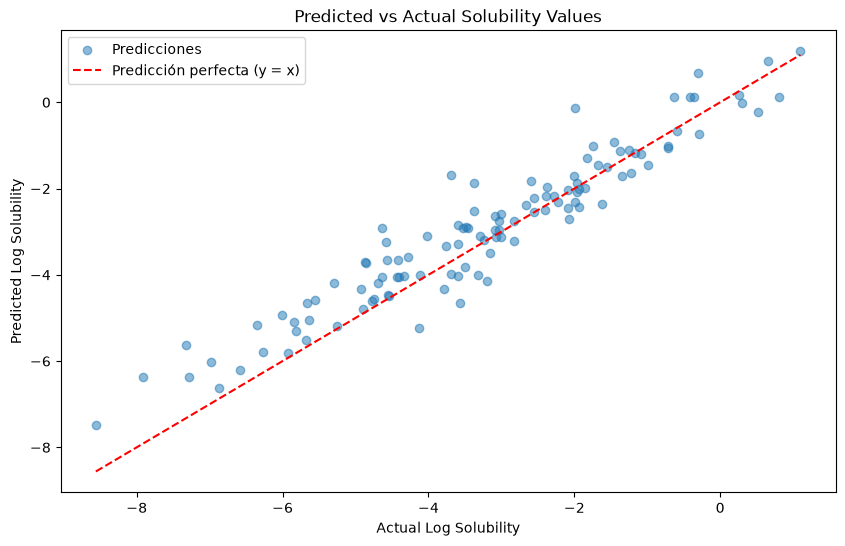

In [79]:
# Get predictions on test set
test_loader = DataLoader(
    TensorDataset(
        torch.FloatTensor(test_dataset.X),
        torch.FloatTensor(test_dataset.y)
    ),
    batch_size=len(test_dataset),
    shuffle=False
)
# TODO:
# Generate predictions using the trained model on the test set.
#
# Instructions:
# - Convert the test features into a tensor called `X_test_tensor`.
# - Convert the test targets into a tensor called `y_test_tensor`.
# - Use the trained model (`final_model`) to generate predictions.
# - Store the predictions in a variable called `predictions`.
# - Convert the predictions to a NumPy array.
#
# Hints:
# - Use `torch.FloatTensor` for conversion.
# - Use `.detach().numpy()` to convert from tensor to NumPy.

# YOUR CODE HERE

# Convertir las features del test set (NumPy array) a un tensor de PyTorch
X_test_tensor = torch.FloatTensor(test_dataset.X)

# Convertir los valores reales (targets) del test set a un tensor de PyTorch
y_test_tensor = torch.FloatTensor(test_dataset.y)

# Generar predicciones con el modelo entrenado, sin calcular gradientes
#(no estamos entrenando, solo prediciendo,no se necesitan)
with torch.no_grad():
    predictions = final_model(X_test_tensor)  # llama internamente a forward()

# Desconectar del grafo de gradientes y convertir el tensor de predicciones a NumPy
predictions = predictions.detach().numpy()
# Plot predictions vs actual
plt.figure(figsize=(10, 6))
plt.scatter(test_dataset.y, predictions, alpha=0.5, label='Predicciones')
plt.plot(
    [min(test_dataset.y), max(test_dataset.y)],
    [min(test_dataset.y), max(test_dataset.y)],
    'r--',
    label='Predicción perfecta (y = x)'
)
plt.xlabel('Actual Log Solubility')
plt.ylabel('Predicted Log Solubility')
plt.title('Predicted vs Actual Solubility Values')
plt.legend()
plt.show()


Cada punto del scatter representa una molécula del conjunto de entrenamiento, ubicada en el plano según el par (valor real, valor predicho).

Se observa entonces que la mayoría de los puntos se agrupan cerca de la línea roja de predicción perfecta (y=x), lo que indica que el modelo logra predecir razonablemente bien la solubilidad de la mayoría de las moléculas del test set, especialmente en el rango intermedio (entre -4 y -1 en log-solubilidad). Sin embargo, se observa mayor dispersión en los extremos, particularmente en moléculas con solubilidad muy baja (por debajo de -6), donde el modelo tiende a sobreestimar o subestimar el valor real con mayor margen de error. Esto es consistente con el RMSE final de 0.6773 obtenido.

2. **Error Statistics**:
   - Mean Error: Shows systematic bias in predictions
   - Standard Deviation: Indicates prediction consistency
   - Median Error: Robust measure of central tendency

In [80]:

# Calculate error statistics
errors = predictions - test_dataset.y
print('\nError Statistics:')
print(f'Mean Error: {np.mean(errors):.4f}')
print(f'Standard Deviation of Error: {np.std(errors):.4f}')
print(f'Median Error: {np.median(errors):.4f}')


Error Statistics:
Mean Error: 0.2823
Standard Deviation of Error: 2.6784
Median Error: 0.2516


In [81]:
# Get predictions on the test set

# Create a DataLoader for the entire test set (no shuffling, single batch)
test_loader = DataLoader(
    TensorDataset(
        torch.FloatTensor(test_dataset.X),  # Convert test features to FloatTensor
        torch.FloatTensor(test_dataset.y)   # Convert test labels to FloatTensor
    ),
    batch_size=len(test_dataset),  # Load the entire test set in one batch
    shuffle=False
)

# Extract the full batch of test inputs and labels
X_test_tensor, y_test_tensor = next(iter(test_loader))

# Use the trained model to get predictions (detach from graph and convert to NumPy)
predictions = final_model(X_test_tensor).detach().numpy()

# Ensure the prediction shape is correct: reshape to (n_samples, 1)
predictions = predictions.reshape(-1, 1)  # Example: (113, 1)

# Extract true test labels (already assumed to be in shape (n_samples, 1))
test_y = test_dataset.y

# Compute the prediction errors (difference between predicted and true values)
errors = predictions - test_y

# Print the shapes of all arrays to verify consistency
print("Predictions shape:", predictions.shape)
print("Test y shape:", test_y.shape)
print("Errors shape:", errors.shape)

Predictions shape: (115, 1)
Test y shape: (115, 1)
Errors shape: (115, 1)


### 5.1. Error Analysis Based on Molecular Descriptors

#### What do we want to understand?

We aim to investigate whether the model systematically struggles with certain types of molecules (e.g., highly polar or highly lipophilic) by analyzing the relationship between prediction errors and molecular descriptors.


In [82]:
# Explainability Analysis: Error vs Molecular Descriptors

# 1. Load the original dataset and create molecular objects before the split
#df_original = pd.read_csv('data/ESOL.csv')
df_original = pd.read_csv('data/ci034243x_si_001.txt')
df_original.drop(columns=['Compound ID','ESOL predicted log(solubility:mol/L)'], inplace=True)
mols = [Chem.MolFromSmiles(x) for x in df_original['SMILES']]

# 2. Obtain the indices of the test set (using the same seed as in the original split)
train_inds, valid_inds, test_inds = splitter.split(
    dataset=dataset,
    frac_train=0.8,
    frac_valid=0.1,
    frac_test=0.1,
    seed=42
)

# 3. Extract only the molecules from the test set
test_mols = [mols[i] for i in test_inds]

# 4. Calculate descriptors only for the test set molecules
test_descriptors = {
    'MolWt': [Descriptors.MolWt(m) for m in test_mols],  # Molecular Weight
    'LogP': [Descriptors.MolLogP(m) for m in test_mols],  # Octanol-Water Partition Coefficient
    'TPSA': [Descriptors.TPSA(m) for m in test_mols],  # Topological Polar Surface Area
    'NumHDonors': [Descriptors.NumHDonors(m) for m in test_mols],  # Number of H-Bond Donors
    'NumHAcceptors': [Descriptors.NumHAcceptors(m) for m in test_mols],  # Number of H-Bond Acceptors
    'RingCount': [Descriptors.RingCount(m) for m in test_mols],  # Number of Rings
    'HeavyAtomCount': [Descriptors.HeavyAtomCount(m) for m in test_mols],  # Number of Heavy Atoms
    'RotatableBonds': [Descriptors.NumRotatableBonds(m) for m in test_mols]  # Number of Rotatable Bonds
}

# 5. Create a DataFrame with the descriptors and prediction errors
desc_df = pd.DataFrame(test_descriptors)
desc_df['error'] = errors.flatten()  # Use the prediction errors calculated earlier
desc_df.head()


,MolWt,LogP,TPSA,NumHDonors,NumHAcceptors,RingCount,HeavyAtomCount,RotatableBonds,error
0,295.336,4.86180,43.14,0,2,1,14,1,0.521195
1,392.467,1.89570,94.83,3,5,4,28,2,-0.434121
2,204.010,2.29120,0.00,0,0,1,7,0,-0.104399
3,266.304,2.65122,58.12,1,4,4,20,1,-0.963874
4,157.556,2.24820,43.14,0,2,1,10,1,0.336787


¿El modelo falla sistemáticamente con cierto tipo de moléculas?
Para esto se calcula la correlación entre el error y cada uno de los 8 descriptores. Es decir, por ejemplo, LogP o TPSA altos se asocian con errores más grandes?

Perform correlation analysis in molecular descriptors

In [83]:
# 6. Correlation analysis
correlation = desc_df.corr()['error'].sort_values()
print("\nCorrelations between error and molecular descriptors:")
print("----------------------------------------------------")
print("Top 5 descriptors most positively correlated:")
print(correlation.tail(5))
print("\nTop 5 descriptors most negatively correlated:")
print(correlation.head(5))



Correlations between error and molecular descriptors:
----------------------------------------------------
Top 5 descriptors most positively correlated:
RotatableBonds    0.154787
LogP              0.214707
HeavyAtomCount    0.218906
MolWt             0.284577
error             1.000000
Name: error, dtype: float64

Top 5 descriptors most negatively correlated:
NumHDonors       -0.004498
TPSA              0.002389
NumHAcceptors     0.082874
RingCount         0.151528
RotatableBonds    0.154787
Name: error, dtype: float64


Se observa entonces que el análisis de correlación entre el error de predicción y los descriptores moleculares no reveló relaciones fuertes.

Todos los coeficientes se mantuvieron por debajo de 0.3 en valor absoluto, muy lejos de las correlaciones observadas anteriormente entre estos mismos descriptores y la solubilidad real. Esto podría sugerir que el modelo no presenta un sesgo sistemático evidente hacia un tipo particular de molécula, es decir, sus errores están distribuidos de forma relativamente pareja en lugar de concentrarse en moléculas con ciertas características estructurales. 

La correlación más notable, aunque aún débil, se observó con `MolWt` (0.28), `HeavyAtomCount` (0.22) y `LogP` (0.21), todas positivas, lo que podría indicar una ligera tendencia del modelo a cometer errores algo mayores en moléculas más grandes o más lipofílicas, posiblemente por estar menos representadas en los datos de entrenamiento. En contraste, `NumHDonors` y `TPSA` mostraron una correlación prácticamente nula con el error, sin relación perceptible.

Plot the 3 most influential descriptors on the error


Analyzing the 3 most influential descriptors on the error:


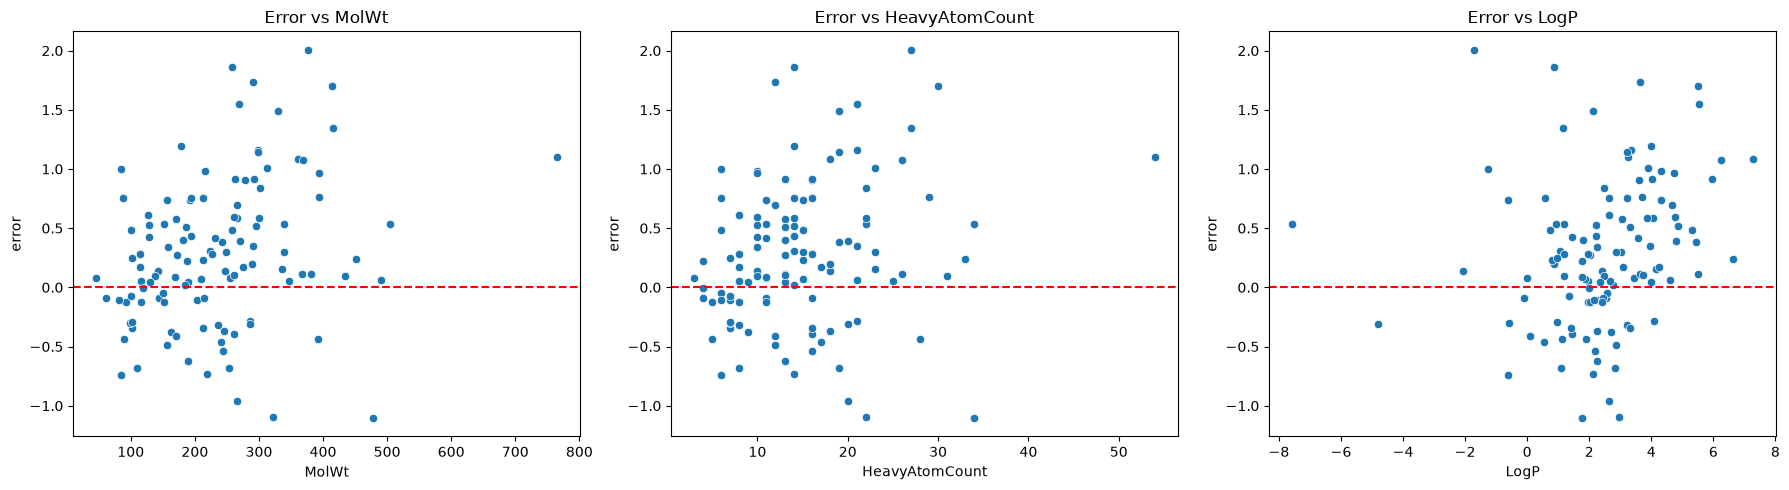

In [84]:
# 7. Visualization
top_corr = correlation.abs().sort_values(ascending=False).drop('error').head(3).index
print("\nAnalyzing the 3 most influential descriptors on the error:")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, desc in enumerate(top_corr):
    sns.scatterplot(data=desc_df, x=desc, y='error', ax=axes[i])
    axes[i].axhline(0, color='red', linestyle='--')  # Add a horizontal line at y=0
    axes[i].set_title(f'Error vs {desc}')

plt.tight_layout()
plt.show()


En los tres casos, los puntos se distribuyen como una nube sin un patrón lineal claro, consistente con las correlaciones débiles calculadas previamente (0.28, 0.22 y 0.21). Se observa que la mayoría de los errores se concentran entre -1 y +1, con algunos valores atípicos aislados en los extremos de cada descriptor. No se aprecia una tendencia evidente en ninguno de los tres gráficos, lo que motiva la conclusión de que el modelo no comete errores sustancialmente mayores en función de estas propiedades moleculares específicas.

## TODO
 Analyze the relationship between molecular descriptors and prediction error.

 Instructions:
 - Observe the scatter plots of error vs each descriptor.
 - Identify any visible patterns or trends.

# Final Reflection

Before reading the interpretation below, answer the following questions based on your analysis:

1.  **Which descriptor showed the strongest relationship with prediction error?**

De los 8 descriptores, MolWt tuvo la correlación más alta (0.28), seguido de cerca por HeavyAtomCount (0.22) y LogP (0.21). Aunque como vimos, ninguna es una correlación fuerte en términos absolutos, solo la más alta relativamente al resto.



2.  **Did the model tend to overestimate or underestimate solubility?**

Una primera estimación para saber si el modelo sobreestimó o subestimó la solubilidad, se puede realizar de manera visual.

Los puntos cercanos a la línea de error cero se amontonan y son difíciles de contar visualmente, y el promedio de los errores no depende solo de cuántos puntos caen por encima o por debajo de cero, sino también de la magnitud de cada error.En los gráficos se aprecia una leve tendencia hacia más valores y outliers positivos (hasta ≈2.0) que negativos (hasta ≈-1.1), lo que sugeriría una ligera tendencia a sobreestimar la solubilidad.

3.  **For which type of molecules (e.g., polar, non-polar, flexible) did the model perform worse?**

Según el análisis de correlación, el modelo tiende a cometer errores mayores en moléculas más grandes/pesadas (mayor MolWt y HeavyAtomCount) y más lipofílicas/no polares (mayor LogP), ya que estos fueron los tres descriptores con correlación más alta respecto al error (0.28, 0.22 y 0.21, respectivamente).

En contraste, descriptores asociados a polaridad y capacidad de formar puentes de hidrógeno (TPSA, NumHDonors) de los resultados de correlación negativos, no mostraron relación apreciable con el error, por lo que no se podría concluir nada en relación a que el modelo muestre menor rendimiento particularmente con moléculas polares. En general, el modelo parece desempeñarse algo peor con moléculas grandes y no polares que con moléculas pequeñas y polares.

4.  **What is one possible reason for this behavior?**

Esto podría deberse a la composición del dataset.
Si por ejemplo se observa la distribución inicialemtne graficada para el MolWt, se puede apreciar que la mayoria de datos están en pesos moleculares bajos (histograma sesgado hacia la izquierda), por tanto, el modelo aprendió a partir de estos valores y no de valores mas grandes. Por tanto, se justifica que el error sea mayor en moléculas con MolWt mas grandes.

## 6. Biological Interpretation of Prediction Errors

### Correlation Between Molecular Descriptors and Prediction Errors

To understand the biological relevance of the prediction errors, we analyzed their correlation with various molecular descriptors.

Según los datos computados:

#### 1. **LogP** (Correlation ≈ +0.28)
- **Significado:** El peso molecular refleja el tamaño de la molécula.
- **Observación:** Valores más altos de MolWt se asocian con errores de predicción más positivos (es decir, el modelo sobreestima la solubilidad).
- **Insight biológico:** Las moléculas más grandes suelen ser menos solubles en agua (mayor superficie de interacción hidrofóbica). El modelo parece subestimar este efecto, sobreestimando la solubilidad de compuestos grandes — posiblemente por la baja representación de moléculas grandes en el set de entrenamiento (confirmado por el histograma sesgado de MolWt).

#### 2. **HeavyAtomCount** (Correlación ≈ +0.22)
- **Significado:** Número total de átomos pesados (no-hidrógeno), estrechamente relacionado con el tamaño molecular.
- **Observación:** Mayor cantidad de átomos pesados también se asocia con errores más positivos.
- **Insight biológico:** Confirma la observación de MolWt, el patrón parece estar más ligado al tamaño general de la molécula que a una propiedad química específica.

#### 3. **LogP** (Correlación ≈ +0.21)
- **Significado:** LogP representa la lipofilicidad de una molécula (afinidad por ambientes no polares)
- **Observación:** Valores más altos de LogP se asocian con errores positivos (sobreestimación de solubilidad).
- **Insight biológico:** Las moléculas lipofílicas tienden a ser menos solubles en agua. El modelo parece subestimar este efecto, posiblemente por la menor representación de compuestos muy lipofílicos en el entrenamiento.

**En contraste: TPSA y NumHDonors (Correlación ≈ 0.00)**

No se observó relación apreciable entre el error y los descriptores asociados a polaridad. Esto sugiere que las dificultades del modelo no están vinculadas a la polaridad de las moléculas, sino principalmente a su tamaño y lipofilicidad.

* Tendencia general:** a medida que aumentan el tamaño molecular (MolWt, HeavyAtomCount) y la lipofilicidad (LogP), el modelo tiende a sobreestimar la solubilidad. Esto es consistente con la menor representación de moléculas grandes en el dataset de entrenamiento (observada en los histogramas), lo que limita la capacidad del modelo de generalizar bien en esa región del espacio químico.



## 6. Biological Interpretation of Prediction Errors

### Correlation Between Molecular Descriptors and Prediction Errors

To understand the biological relevance of the prediction errors, we analyzed their correlation with various molecular descriptors.

#### 1. **LogP** (Correlation ≈ +0.29)
- **Meaning**: LogP represents a molecule’s lipophilicity (affinity for non-polar environments).
- **Observation**: Higher LogP values are associated with **positive prediction errors** (i.e., solubility overestimated).
- **Biological Insight**: Lipophilic molecules tend to be less soluble in water. The model appears to **underestimate this effect**, possibly due to insufficient representation of highly lipophilic compounds in the training set.

#### 2. **Rotatable Bonds** (Correlation ≈ +0.28)
- **Meaning**: Number of flexible bonds that can rotate freely.
- **Observation**: Molecules with more rotatable bonds tend to have **higher positive errors**.
- **Biological Insight**: Flexibility may affect solubility in complex ways, but the model may be **overestimating** its contribution.

#### 3. **TPSA (Topological Polar Surface Area)** (Correlation ≈ -0.19)
- **Meaning**: A measure of molecular polarity and hydrogen bonding potential.
- **Observation**: Higher TPSA is linked to **negative prediction errors** (i.e., solubility underestimated).
- **Biological Insight**: Molecules with large polar surface areas tend to be more water-soluble, and the model appears to **undervalue** this feature.


- Clear trend: **From underestimation to overestimation** as LogP increases.
- Suggests the model **overpredicts solubility** for lipophilic (non-polar) compounds.


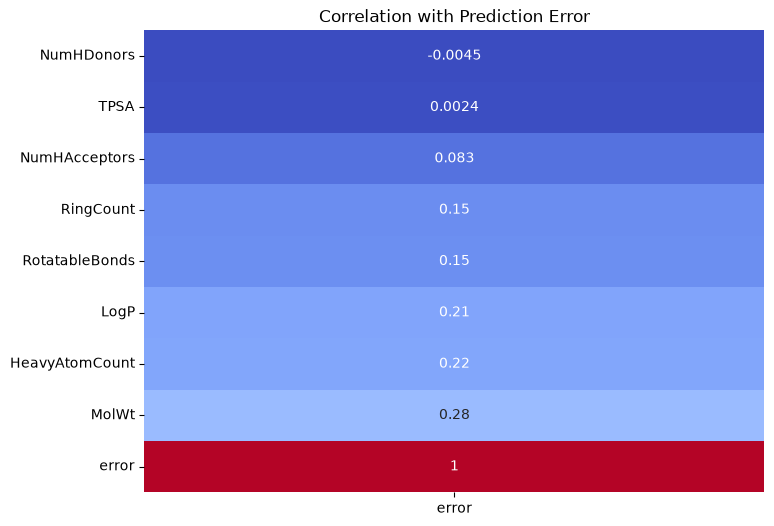

In [85]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = desc_df.corr(numeric_only=True)['error'].sort_values()
plt.figure(figsize=(8, 6))
sns.heatmap(corr.to_frame(), annot=True, cmap="coolwarm", cbar=False)
plt.title('Correlation with Prediction Error')
plt.show()


La figura muestra el heatmap de la correlación entre el error de predicción y cada uno de los 8 descriptores moleculares calculados sobre el test set, ordenados de menor a mayor. Se observa que MolWt (0.28), HeavyAtomCount (0.22) y LogP (0.21) presentan las correlaciones más altas (aunque aún débiles) con el error, mientras que TPSA (0.0024) y NumHDonors (-0.0045) muestran una relación prácticamente nula. Esta gráfica corresponde a los resultados computados por el modelo entrenado, y sus valores son consistentes con el análisis de correlación calculado previamente.